# Avance: tabla de víctimas y victimarios

**Fuente:** mapa *Extorsión y Crímenes Violentos – Perú [2026]* (uMap / @e_incidentsperu), 1,106 incidentes.

**Objetivo del avance:** pasar de una tabla de *incidentes* (una fila por hecho) a una tabla de *actores*, donde **cada fila es una persona o empresa afectada, o un victimario**, y las columnas son sus atributos (nombre, sexo, edad, ocupación/rubro, antecedentes, estado, etc.).

**Método:** el CSV solo trae un titular corto por incidente. El script `src/extraer_actores.py` lee cada titular con reglas (expresiones regulares + diccionarios de ocupaciones, nacionalidades, tipos de objetivo) y genera una fila por actor. Cada fila guarda la `frase_detectada` y la `regla` usada, para poder revisarla a mano.

In [1]:
import sys
sys.path.insert(0, "../src")
import pandas as pd
import matplotlib.pyplot as plt
import extraer_actores as ea

pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 80)

incidentes, actores = ea.main("../data/extorsion_y_crimenes_violentos_peru_2026.csv", "../salida")

Incidentes: 1106
Filas de actores: 2685
rol         tipo_actor                   
Victimario  Persona                          1119
Víctima     Empresa / institución (sigla)       3
            Empresa / negocio                  81
            Institución                        18
            Objetivo sin clasificar             6
            Persona                          1200
            Sin víctima identificada           88
            Vehículo                          113
            Vivienda                           57


## 1. La tabla de actores (primeras filas)

In [2]:
cols = ["id_actor", "id_incidente", "fecha", "tipo_evento", "rol", "tipo_actor", "cantidad",
        "nombre_o_alias", "sexo", "edad", "grupo_etario", "nacionalidad", "ocupacion", "rubro",
        "organizacion_vinculada", "antecedentes", "estado_o_situacion", "titular"]
actores[cols].head(20)

,id_actor,id_incidente,fecha,tipo_evento,rol,tipo_actor,cantidad,nombre_o_alias,sexo,edad,grupo_etario,nacionalidad,ocupacion,rubro,organizacion_vinculada,antecedentes,estado_o_situacion,titular
0,A00001,I0001,2026-09-10,Balacera,Víctima,Persona,1,,Sin dato,<NA>,Sin dato,Sin dato,Sin dato,Sin dato,,Sin dato,Herido,"Balacera entre grupos deja 1 herido en parque ""Virgen del Carmen"" en Urb. Co..."
1,A00002,I0001,2026-09-10,Balacera,Victimario,Persona,2 o más (sin número),,Sin dato,<NA>,Sin dato,Sin dato,Grupos enfrentados,Sin dato,,Sin dato,No capturado / sin dato,"Balacera entre grupos deja 1 herido en parque ""Virgen del Carmen"" en Urb. Co..."
2,A00003,I0002,2026-01-02,Agresión,Víctima,Persona,1,,Masculino,<NA>,Sin dato,Sin dato,Sin dato,Sin dato,,Sin dato,Herido,"Sujeto acuchilla a padre de familia frente a su hija en Av. 12 de Octubre, z..."
3,A00004,I0002,2026-01-02,Agresión,Victimario,Persona,1,,Sin dato,<NA>,Sin dato,Sin dato,Sujeto(s) no identificado(s),Sin dato,,Sin dato,No capturado / sin dato,"Sujeto acuchilla a padre de familia frente a su hija en Av. 12 de Octubre, z..."
4,A00005,I0003,2026-02-02,Agresión,Víctima,Persona,2 o más (sin número),,Sin dato,<NA>,Sin dato,Sin dato,Sin dato,Sin dato,,Sin dato,Herido,Barristas de la U agreden y hieren a varias personas en Av. Rosa Luz y calle...
5,A00006,I0003,2026-02-02,Agresión,Victimario,Persona,1,,Sin dato,<NA>,Sin dato,Sin dato,No especificado,Sin dato,,Sin dato,No capturado / sin dato,Barristas de la U agreden y hieren a varias personas en Av. Rosa Luz y calle...
6,A00007,I0004,2026-02-24,Agresión,Víctima,Vehículo,1,,Sin dato,<NA>,Sin dato,Sin dato,Sin dato,Transporte,,Sin dato,Atacado (daños materiales),Barristas atacan couster y otros vehículos en Av. La Marina frente a estació...
7,A00008,I0004,2026-02-24,Agresión,Víctima,Vehículo,1,,Sin dato,<NA>,Sin dato,Sin dato,Sin dato,Transporte,,Sin dato,Atacado (daños materiales),Barristas atacan couster y otros vehículos en Av. La Marina frente a estació...
8,A00009,I0004,2026-02-24,Agresión,Víctima,Persona,1,,Sin dato,<NA>,Sin dato,Sin dato,Sin dato,Sin dato,,Sin dato,Herido,Barristas atacan couster y otros vehículos en Av. La Marina frente a estació...
9,A00010,I0004,2026-02-24,Agresión,Víctima,Persona,1,,Sin dato,<NA>,Sin dato,Sin dato,Sin dato,Sin dato,,Sin dato,Herido,Barristas atacan couster y otros vehículos en Av. La Marina frente a estació...


### Diccionario de columnas

In [3]:
diccionario = pd.DataFrame([
    ("id_actor", "Identificador de la fila (actor)"),
    ("id_incidente", "Incidente al que pertenece (une con incidentes.csv)"),
    ("rol", "Víctima o Victimario"),
    ("tipo_actor", "Persona, Empresa / negocio, Vehículo, Vivienda, Institución"),
    ("cantidad", "1 = una persona por fila; '2 o más (sin número)' cuando el titular dice 'sicarios', 'hombres', etc."),
    ("nombre_o_alias", "Nombre propio o alias si el titular lo menciona"),
    ("sexo / edad / grupo_etario", "Solo si el titular lo dice (hombre, mujer, 'de 17 años', menor, joven...)"),
    ("nacionalidad", "Si el titular la menciona (venezolano, extranjero...)"),
    ("ocupacion / rubro", "Oficio de la víctima (chofer, mototaxista, policía...) y su sector; en victimarios, el tipo (sicario, extorsionador...)"),
    ("organizacion_vinculada", "Empresa, línea o ruta mencionada (ej. 'Etmosa', 'Línea 129')"),
    ("antecedentes", "'Sí' / 'Posible' solo si el titular lo indica (alias, 'tenía antecedentes', recluso...)"),
    ("estado_o_situacion", "Víctimas: fallecido, herido, herido grave, secuestrado, atacado (daños)...; victimarios: capturado, abatido, sin dato"),
    ("medio_empleado / movil_presunto", "Arma de fuego, explosivo, arma blanca, incendio / extorsión, robo, enfrentamiento"),
    ("ambito", "Lima Metropolitana y Callao (recuadro aproximado) u otras regiones"),
    ("frase_detectada / regla", "Trozo del titular de donde salió la fila y la regla aplicada (para revisar)"),
], columns=["columna", "descripción"])
diccionario

,columna,descripción
0,id_actor,Identificador de la fila (actor)
1,id_incidente,Incidente al que pertenece (une con incidentes.csv)
2,rol,Víctima o Victimario
3,tipo_actor,"Persona, Empresa / negocio, Vehículo, Vivienda, Institución"
4,cantidad,1 = una persona por fila; '2 o más (sin número)' cuando el titular dice 'sic...
5,nombre_o_alias,Nombre propio o alias si el titular lo menciona
6,sexo / edad / grupo_etario,"Solo si el titular lo dice (hombre, mujer, 'de 17 años', menor, joven...)"
7,nacionalidad,"Si el titular la menciona (venezolano, extranjero...)"
8,ocupacion / rubro,"Oficio de la víctima (chofer, mototaxista, policía...) y su sector; en victi..."
9,organizacion_vinculada,"Empresa, línea o ruta mencionada (ej. 'Etmosa', 'Línea 129')"


## 2. Resumen de víctimas

In [4]:
vict = actores[actores["rol"] == "Víctima"]
personas = vict[vict["tipo_actor"] == "Persona"]
print(f"Incidentes: {len(incidentes)} | filas de actores: {len(actores)}")
print(f"Víctimas personas: {len(personas)} | objetivos materiales (vehículos, negocios, viviendas...): "
      f"{(~vict['tipo_actor'].isin(['Persona', 'Sin víctima identificada'])).sum()}")
pd.crosstab(vict["tipo_actor"], vict["estado_o_situacion"], margins=True, margins_name="Total")

Incidentes: 1106 | filas de actores: 2685
Víctimas personas: 1200 | objetivos materiales (vehículos, negocios, viviendas...): 278


estado_o_situacion,Amenazado,Atacado (daños materiales),Atacado (ileso),Fallecido,Herido,Herido (estado desconocido),Herido (sobrevivió),Herido grave,Secuestrado,Secuestrado (liberado),Sin dato,Sin heridos reportados,Total
tipo_actor,,,,,,,,,,,,,
Empresa / institución (sigla),0,3,0,0,0,0,0,0,0,0,0,0,3
Empresa / negocio,0,81,0,0,0,0,0,0,0,0,0,0,81
Institución,0,18,0,0,0,0,0,0,0,0,0,0,18
Objetivo sin clasificar,0,6,0,0,0,0,0,0,0,0,0,0,6
Persona,7,1,14,586,436,47,4,92,6,7,0,0,1200
Sin víctima identificada,0,0,0,0,0,0,0,0,0,0,61,27,88
Vehículo,0,113,0,0,0,0,0,0,0,0,0,0,113
Vivienda,0,57,0,0,0,0,0,0,0,0,0,0,57
Total,7,279,14,586,436,47,4,92,6,7,61,27,1566


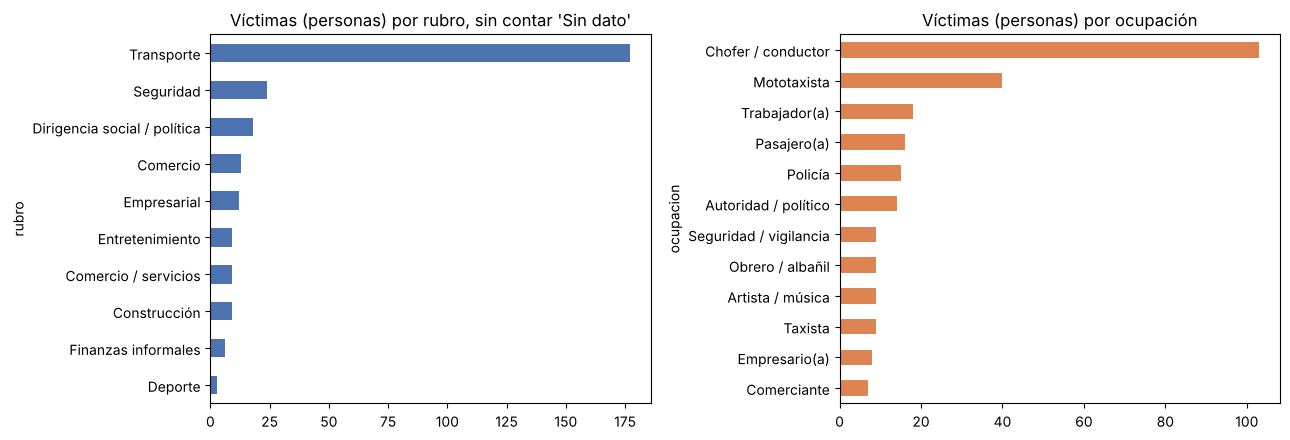

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
personas["rubro"].value_counts().drop("Sin dato", errors="ignore").head(10).sort_values().plot.barh(ax=ax[0], color="#4C72B0")
ax[0].set_title("Víctimas (personas) por rubro, sin contar 'Sin dato'")
personas["ocupacion"].value_counts().drop("Sin dato", errors="ignore").head(12).sort_values().plot.barh(ax=ax[1], color="#DD8452")
ax[1].set_title("Víctimas (personas) por ocupación")
plt.tight_layout()

In [6]:
pd.concat({
    "sexo": personas["sexo"].value_counts(),
    "grupo_etario": personas["grupo_etario"].value_counts(),
}, axis=0).to_frame("víctimas")

víctimas
sexo         Sin dato                  803
             Masculino                 305
             Femenino                   92
grupo_etario Sin dato                 1108
             Joven                      51
             Menor de edad              19
             Niño(a) (<12)              10
             Adolescente (12-17)         9
             Adulto (30-59)              1
             Adulto mayor (60+)          1
             Joven (18-29)               1

## 3. Resumen de victimarios

In [7]:
vrios = actores[actores["rol"] == "Victimario"]
pd.crosstab(vrios["ocupacion"], vrios["estado_o_situacion"], margins=True, margins_name="Total").sort_values("Total", ascending=False)

estado_o_situacion,Abatido / muerto,Capturado,No capturado / sin dato,Total
ocupacion,,,,
Total,6,42,1071,1119
Sicario,2,4,590,596
No especificado,1,22,295,318
Sujeto(s) no identificado(s),0,9,145,154
Persona particular,0,3,16,19
Ladrón,2,3,7,12
Grupos enfrentados,1,0,10,11
Delincuente,0,0,6,6
Grupo armado / terrorista,0,1,1,2


## 4. Incidentes en el tiempo

tipo_evento,Agresión,Asesinato,Atentado,Balacera,Explosivo,Extorsión,Secuestro
fecha,,,,,,,
2025-01,0,1,0,0,0,1,0
2026-01,1,48,31,42,9,4,2
2026-02,3,53,25,47,2,2,0
2026-03,1,39,15,31,0,2,0
2026-04,0,26,9,29,0,1,0
2026-05,3,55,6,44,2,1,1
2026-06,0,42,11,28,1,0,0
2026-07,2,50,14,46,1,3,0
2026-08,1,53,12,42,4,1,1


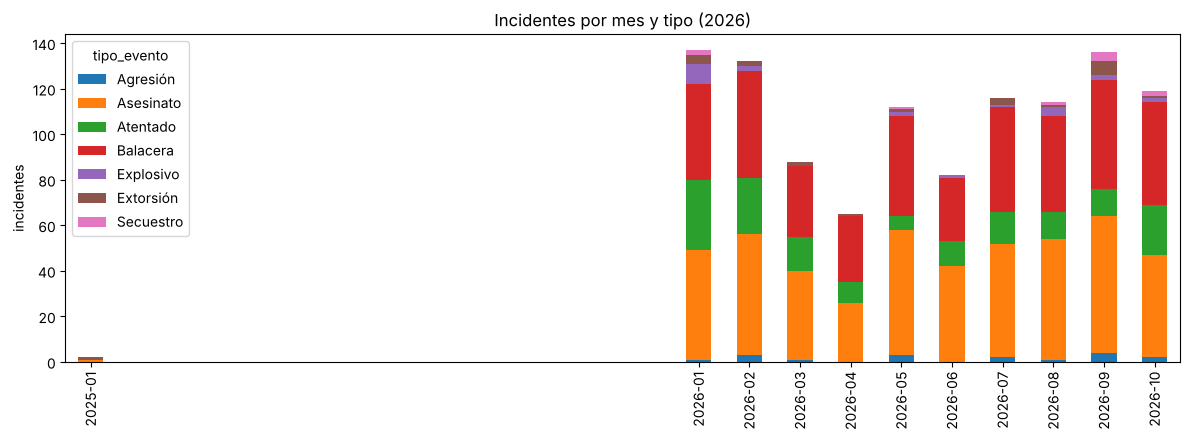

In [8]:
tabla_mes = pd.crosstab(incidentes["fecha"].dt.to_period("M"), incidentes["tipo_evento"])
tabla_mes.plot.bar(stacked=True, figsize=(12, 4.5), title="Incidentes por mes y tipo (2026)")
plt.ylabel("incidentes"); plt.xlabel(""); plt.tight_layout()
tabla_mes

## 5. Limitaciones y siguientes pasos

- **El titular es corto** (~76 caracteres). Por eso nombre, edad, antecedentes y nacionalidad casi siempre quedan en *Sin dato*: el dato no está en el CSV, está en la noticia enlazada (`fuente_url`).
- **Reglas, no lectura humana.** Las reglas cubren las formas más comunes ("Sicarios asesinan a…", "Balacera deja N heridos", "Detonan explosivo en…"). Revisamos a mano decenas de casos, pero puede haber errores; las columnas `frase_detectada` y `regla` permiten corregirlos.
- **Victimarios**: casi nunca se identifican; la fila registra el tipo (sicario, extorsionador…) y si fue capturado.
- **Siguientes pasos**: (1) revisar y corregir una muestra, (2) completar atributos leyendo las noticias enlazadas, (3) añadir la base 2025, (4) usar la tabla de incidentes (fecha + lat/lon) para los modelos espacio-temporales (repetición cercana / Hawkes).